# Active lattice gas — Persistent Exclusion Process (PEP), v1

这是一份从旧 `lattice_gas_mc` 延伸的独立 notebook。先理解并验证 active dynamics，随后运行一个固定预算的有限时间示例。

**模型选择：** 采用 Soto & Golestanian (2014) 的二维 PEP。保留方格、周期边界、固定粒子数和旧结构测量；用带朝向的 run-and-tumble 更新替代 Kawasaki/Metropolis 更新。**本版没有吸引能、温度参数、alignment 或粒子插入/删除。它不是在原 attractive 模型上简单调高温度。** 这是用于学习和实现的起始模型，不预先指定为最终 thesis 模型。

文献：[Phys. Rev. E 89, 012706](https://doi.org/10.1103/PhysRevE.89.012706)，[arXiv:1306.0481v2](https://arxiv.org/abs/1306.0481v2)，Section II。

**本次问题：** 实现是否满足规定的随机顺序更新、排斥和粒子数守恒，并通过已知极限检查？有限时间示例展示哪些结构和运动记录？

**成功条件：** 确定性运动检查、独立参考事件比较、alpha=1 的精确 occupation 转移矩阵、观测量检查和 checkpoint 重放全部通过。
**失败与停止：** 任一实现检查失败就停止；示例结束于预设 500 sweeps，不因图像不明显而加长或换 seed。没有冻结物理准确度或稳态 PASS，因此不会给出此类结论。

旧 20×20 equilibrium reference 的 NOT READY 决定保持不变。本 notebook 不重启原来的 reference qualification、Track B 或 expTM 训练。

## 使用方法

1. 把本文件放在项目中新建的 `lattice-gas-active` 文件夹。
2. 在 VS Code 选择已有能 import NumPy/Matplotlib 的 Python kernel。无需 PyTorch 或 GPU。
3. 从上到下运行；实现检查和已保存结果可先查看。
4. 首次运行演示时，在第 5 节设置 `RUN_DEMO = True`，只运行该 cell，然后运行绘图 cell。
5. 默认 `RUN_DEMO = False`：完整包中已有 `example_run/`，绘图会读取它；单独下载 notebook 时仍可查看保存的输出，或自己运行演示。

若缺依赖，可在该 kernel 的新 cell 执行 `%pip install numpy matplotlib`，再 restart kernel。不要在旧 notebook 中 Run All。


## 1 — 状态、参数和时间单位

- 每个格点最多一个粒子，$N=\rho L^2$ 固定；网格是 $L\times L$，不是参数扫描网格。
- 每个粒子持有朝向 $\mathbf e\in\{(1,0),(-1,0),(0,1),(0,-1)\}$。
- 一次 attempt：均匀选一个粒子；以概率 $\alpha$ 从**全部四个方向**均匀重选朝向（允许选回原方向）；尝试向该方向移动一格，仅在目标为空时移动。
- 一次 sweep = **N 次有放回的粒子选择**。这与旧 Kawasaki 的 $L^2$ 次 bond proposals 不同，sweep 数不能直接比较成本或物理时间。
- 本版沿论文用 **tumble probability α** 作直接控制量。可同时报告 $A=1/\alpha$ 作为 persistence control；它不是 ABP 的 Pe，也不是 expTM prior variance。
- $\alpha=1$：每次重选方向，occupation dynamics 退化为 symmetric exclusion process (SEP)。$0<\alpha<1$：有运动持续性。$\alpha=0$ 只用于极限测试，不进入示例。

对单粒子的连续更新序号 $k$，朝向核为 $Q=(1-\alpha)I+\alpha\mathbf 1\mathbf 1^T/4$，因此 $\mathbb E[\mathbf e_k\cdot\mathbf e_0]=(1-\alpha)^k$。$1/\alpha$ 是平均两次 tumble 尝试之间的单粒子更新数；它不是实际拥挤环境中的行程长度。实际改变方向的概率是 $3\alpha/4$。

固定 density 下，平均占据率始终是输入值，因此它不是 activity–density 图的结构色标。这里记录 $S_{low}$、最大团块比例 $f_{max}$、local-density variance、移动成功率及绕周期边界的 wrapping。它们是候选 observables，不是自动的相分类器。


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations
import copy
import hashlib
import json
import platform
import time
import uuid
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
OUTPUT_ROOT = PROJECT_DIR / "runs_pep"
DIRECTIONS = np.array([[1, 0], [-1, 0], [0, 1], [0, -1]], dtype=np.int64)
DIRECTION_NAMES = ["+row", "-row", "+column", "-column"]

print("Python:", platform.python_version(), "NumPy:", np.__version__)
print("Working directory:", PROJECT_DIR)


Python: 3.12.14 NumPy: 2.3.5
Working directory: /workspace/scratch/ca1b66dacca0/active_pep_v1


In [2]:
PARENT_NOTEBOOK_SHA256 = 'ec8e2fd1d3e26619db82a6033bead133ea8586953e0331f3c865b567a6a578b4'
REUSED_FUNCTION_SHA256 = {'count_boundary_bonds': 'fd471f3159b5d84b7cc7765fd621007d43c49d67e9fadf5003881c42dad5da14', 'lowest_mode_structure': 'd26be8bf002e972d92061d349791189a8300b6c9456297c254c228da87707028', 'periodic_cluster_observables': 'adc5b8dfd54c014c92f10c066786f5ef30f498216a96c837f7520617bc9e93de'}
PROVENANCE = {
    "parent_filename": "lattice_gas_mc(1).ipynb",
    "parent_notebook_sha256": PARENT_NOTEBOOK_SHA256,
    "reused_function_sha256": REUSED_FUNCTION_SHA256,
    "model_reference": "Soto and Golestanian, PRE 89, 012706 (2014), Section II",
    "doi": "10.1103/PhysRevE.89.012706",
    "reused": "Periodic geometry, fixed N, and three unmodified structural functions",
    "new": "Particle orientations, PEP updates, state/checkpoint handling, local-density measure",
    "removed_from_active_dynamics": "Attraction energy, Metropolis acceptance, chemical potential, PT",
    "previous_reference_status": "NOT_READY_PRECISION_SCREEN_NOT_MET; unchanged",
}


## 2 — 模拟核心

`owner[row, column]` 存 particle ID，空格为 −1；`positions[id]` 和 `orientation[id]` 保存同一粒子的状态。
即使前方被堵住，粒子也可以 tumble。禁止同步移动、交换两个占据格点或仅在移动成功后更新朝向。


In [3]:
def make_state(L, density, rng, initial="random"):
    if isinstance(L, bool) or int(L) != L or L < 3:
        raise ValueError("L must be an integer >= 3.")
    L = int(L)
    if not np.isfinite(density) or not 0 <= density <= 1:
        raise ValueError("density must be in [0, 1].")
    target = float(density) * L * L
    N = int(round(target))
    if not np.isclose(target, N, rtol=0, atol=1e-9):
        raise ValueError("Choose a density with integer density * L**2; no silent rounding.")
    if initial == "random":
        flat = rng.choice(L * L, size=N, replace=False)
    elif initial == "stripe":
        flat = np.arange(N)  # Filled rows; a partial final row is allowed.
    else:
        raise ValueError("initial must be 'random' or 'stripe'.")
    positions = np.column_stack(np.unravel_index(flat, (L, L))).astype(np.int64)
    owner = np.full((L, L), -1, dtype=np.int64)
    if N:
        owner[positions[:, 0], positions[:, 1]] = np.arange(N)
    state = dict(L=L, N=N, owner=owner, positions=positions,
                 orientation=rng.integers(0, 4, size=N, dtype=np.int8))
    assert_state(state)
    return state


def assert_state(state):
    L, N = state["L"], state["N"]
    pos, owner, ori = state["positions"], state["owner"], state["orientation"]
    assert owner.shape == (L, L) and pos.shape == (N, 2) and ori.shape == (N,)
    assert np.all((pos >= 0) & (pos < L))
    assert np.all((ori >= 0) & (ori < 4))
    assert np.all((owner >= -1) & (owner < N))
    assert np.count_nonzero(owner >= 0) == N
    if N:
        assert len(np.unique(pos[:, 0] * L + pos[:, 1])) == N
        assert np.array_equal(owner[pos[:, 0], pos[:, 1]], np.arange(N))
    return True


def occupancy(state):
    return (state["owner"] >= 0).astype(np.int8)


def orientation_field(state):
    field = np.full((state["L"], state["L"]), -1, dtype=np.int8)
    if state["N"]:
        p = state["positions"]
        field[p[:, 0], p[:, 1]] = state["orientation"]
    return field


def attempt_event(state, particle_id, tumble, new_direction):
    """One already-selected event. Tumble precedes the exclusion test."""
    if tumble:
        state["orientation"][particle_id] = new_direction
    i, j = state["positions"][particle_id]
    di, dj = DIRECTIONS[state["orientation"][particle_id]]
    k, ell = (i + di) % state["L"], (j + dj) % state["L"]
    if state["owner"][k, ell] >= 0:
        return False
    state["owner"][i, j] = -1
    state["owner"][k, ell] = particle_id
    state["positions"][particle_id] = (k, ell)
    return True


def pep_sweep(state, alpha, rng):
    """N asynchronous attempts, particle selections with replacement."""
    if not np.isfinite(alpha) or not 0 <= alpha <= 1:
        raise ValueError("alpha must be in [0, 1].")
    N = state["N"]
    if N == 0:
        return 0, 0
    # Pre-draw random events; APPLY them sequentially to the evolving state.
    ids = rng.integers(0, N, size=N)
    tumble_uniforms = rng.random(N)
    new_dirs = rng.integers(0, 4, size=N)
    moved = 0
    for pid, u, direction in zip(ids, tumble_uniforms, new_dirs):
        moved += attempt_event(state, int(pid), u < alpha, int(direction))
    return int(moved), N


## 3 — 复用旧结构测量

下面三个函数直接取自上传的旧 notebook，函数源码 hash 已记录。`S_low` 使用 $|FFT(n-ho)|^2/L^2$ 归一化；聚类按四邻接及周期边界定义。
新增 local density 使用周期滑动窗口；相邻窗口高度重叠，不能当作独立样本估计 SEM。


In [4]:
def count_boundary_bonds(n):
    """Count occupied-empty nearest-neighbor bonds once each."""
    return int(
        np.count_nonzero(n != np.roll(n, -1, axis=0))
        + np.count_nonzero(n != np.roll(n, -1, axis=1))
    )

def lowest_mode_structure(n):
    """Mean S(k)=|FFT(n-rho)|^2/M over the four smallest axial modes."""
    fluctuation = n.astype(float) - n.mean()
    spectrum = np.abs(np.fft.fft2(fluctuation)) ** 2 / n.size
    return float(
        (
            spectrum[1, 0] + spectrum[-1, 0]
            + spectrum[0, 1] + spectrum[0, -1]
        ) / 4
    )

def periodic_cluster_observables(state):
    """Measure occupied clusters and closed-path winding on a 2D torus."""
    a = np.asarray(state)
    if (
        a.ndim != 2
        or min(a.shape) < 3
        or not np.isin(a, [0, 1]).all()
    ):
        raise ValueError(
            "A binary 2D array with each dimension >= 3 is required."
        )

    occupied = a == 1
    shape = np.array(a.shape, dtype=int)
    labels = np.full(a.shape, -1, dtype=int)
    lift = np.zeros((*a.shape, 2), dtype=int)
    components = []

    for root in zip(*np.nonzero(occupied)):
        if labels[root] >= 0:
            continue

        cid = len(components)
        labels[root] = cid
        stack = [root]
        size = 0
        wraps = np.zeros(2, dtype=bool)
        basis = None
        rank = 0

        while stack:
            i, j = stack.pop()
            size += 1

            for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                neighbor = (
                    (i + di) % a.shape[0],
                    (j + dj) % a.shape[1],
                )
                if not occupied[neighbor]:
                    continue

                proposed = lift[i, j] + (di, dj)

                if labels[neighbor] < 0:
                    labels[neighbor] = cid
                    lift[neighbor] = proposed
                    stack.append(neighbor)
                else:
                    assert labels[neighbor] == cid

                    # Two paths reach the same periodic site.
                    mismatch = proposed - lift[neighbor]
                    assert np.all(mismatch % shape == 0)
                    winding = mismatch // shape

                    if np.any(winding):
                        wraps |= winding != 0

                        if basis is None:
                            basis = winding.copy()
                            rank = 1
                        elif (
                            basis[0] * winding[1]
                            - basis[1] * winding[0]
                        ) != 0:
                            rank = 2

        components.append({
            "size": size,
            "wrap_axis0": bool(wraps[0]),
            "wrap_axis1": bool(wraps[1]),
            "winding_rank": rank,
        })

    n = int(occupied.sum())
    largest = max((c["size"] for c in components), default=0)
    assert sum(c["size"] for c in components) == n

    return {
        "N": n,
        "n_clusters": len(components),
        "f_max": largest / n if n else 0.0,
        "components": components,
    }


In [5]:
def local_density_field(n, width=5):
    if int(width) != width or width < 1 or width > min(n.shape):
        raise ValueError("width must be an integer between 1 and L.")
    w = int(width)
    total = np.zeros(n.shape, dtype=float)
    for di in range(w):
        for dj in range(w):
            total += np.roll(n, (di, dj), axis=(0, 1))
    return total / w**2


def measure(state, window=5):
    n = occupancy(state)
    clusters = periodic_cluster_observables(n)
    local = local_density_field(n, min(window, state["L"]))
    S = lowest_mode_structure(n)
    N, M = state["N"], n.size
    # Exact nonzero-wavevector mean for uniform fixed-N occupations (SEP).
    sep_S = N * (M - N) / (M * (M - 1))
    return dict(density=float(n.mean()), S_low=S, sep_S_low_reference=sep_S,
                f_max=clusters["f_max"], n_clusters=clusters["n_clusters"],
                boundary=count_boundary_bonds(n),
                local_density_variance=float(local.var()),
                wraps_any=any(c["winding_rank"] > 0 for c in clusters["components"]))


## 4 — 先检查实现，再看图

这些检查针对 update rule 和 bookkeeping，不判断 steady state 或 MIPS。

1. 确定性事件：跨边界、排斥、tumble 后再移动、堵住时仍可转向、alpha=0 的直线运动。
2. 与独立的集合占据实现逐事件比较，检查固定输入下的方向、位置一致性。
3. alpha=1 时枚举 3×3、N=2 的 36 个 occupation states，验证转移矩阵对称及固定 N 均匀分布的 stationarity。
4. 对这 36 个构型独立检查 `S_low` 的均值及旧 cluster 函数的已知构型。
5. 比较连续运行与保存/恢复 RNG 后运行的状态；这只是同一环境内重放。


In [6]:
def run_implementation_checks():
    checks = {}
    rng = np.random.default_rng(2026111130)
    s = make_state(5, 1/25, rng)
    s["owner"][:] = -1
    s["positions"][0] = (0, 4)
    s["owner"][0, 4] = 0
    s["orientation"][0] = 2
    assert attempt_event(s, 0, False, 1)
    assert tuple(s["positions"][0]) == (0, 0)
    assert_state(s)
    assert attempt_event(s, 0, True, 1)
    assert tuple(s["positions"][0]) == (4, 0)
    checks["periodic_move_and_tumble_before_hop"] = True

    full = make_state(5, 1.0, rng)
    previous = full["positions"].copy()
    new_direction = (int(full["orientation"][0]) + 1) % 4
    assert not attempt_event(full, 0, True, new_direction)
    assert full["orientation"][0] == new_direction
    assert np.array_equal(full["positions"], previous)
    assert pep_sweep(full, 1.0, rng)[0] == 0
    assert_state(full)
    checks["exclusion_and_blocked_tumbling"] = True

    s = make_state(7, 1/49, rng)
    initial_pos = s["positions"].copy()
    initial_ori = s["orientation"].copy()
    for _ in range(11):
        moved, attempts = pep_sweep(s, 0, rng)
        assert moved == attempts == 1
    assert np.array_equal(s["orientation"], initial_ori)
    assert np.array_equal(s["positions"], (initial_pos + 11*DIRECTIONS[initial_ori]) % 7)
    empty = make_state(5, 0.0, rng)
    assert pep_sweep(empty, 0.1, rng) == (0, 0)
    checks["ballistic_and_empty_limits"] = True

    s = make_state(7, 20/49, rng)
    ref_positions = [tuple(p) for p in s["positions"]]
    ref_directions = s["orientation"].copy()
    reference_vectors = ((1,0),(-1,0),(0,1),(0,-1))
    for _ in range(2000):
        pid = int(rng.integers(s["N"]))
        tumble, newdir = bool(rng.random() < 0.2), int(rng.integers(4))
        if tumble:
            ref_directions[pid] = newdir
        r, c = ref_positions[pid]
        dr, dc = reference_vectors[int(ref_directions[pid])]
        target = ((r+dr) % 7, (c+dc) % 7)
        expected = target not in set(ref_positions)
        if expected:
            ref_positions[pid] = target
        assert attempt_event(s, pid, tumble, newdir) == expected
        assert np.array_equal(s["positions"], ref_positions)
        assert np.array_equal(s["orientation"], ref_directions)
        assert_state(s)
    checks["independent_reference_2000_events"] = True

    states = list(combinations(range(9), 2))
    index = {x:i for i,x in enumerate(states)}
    P = np.zeros((len(states), len(states)))
    mean_structure = []
    for i, sites in enumerate(states):
        grid = np.zeros((3,3), dtype=np.int8)
        grid.flat[list(sites)] = 1
        mean_structure.append(lowest_mode_structure(grid))
        for start in sites:
            r,c = divmod(start,3)
            for dr,dc in reference_vectors:
                target = ((r+dr)%3)*3 + (c+dc)%3
                result = sites if target in sites else tuple(sorted((set(sites)-{start})|{target}))
                P[i,index[result]] += 1/8
    pi = np.full(len(states), 1/len(states))
    assert np.allclose(P.sum(axis=1),1,rtol=0,atol=1e-14)
    assert np.allclose(P,P.T,rtol=0,atol=1e-14)
    assert np.allclose(pi@P,pi,rtol=0,atol=1e-14)
    assert np.isclose(np.mean(mean_structure),2*7/(9*8),rtol=0,atol=1e-14)
    checks["exact_SEP_36_states_and_structure_reference"] = True

    for alpha in (0.0,0.05,1.0):
        Q = (1-alpha)*np.eye(4)+alpha*np.ones((4,4))/4
        assert np.allclose(Q@DIRECTIONS,(1-alpha)*DIRECTIONS)
    checks["analytic_orientation_kernel"] = True

    seam = np.zeros((8,8),dtype=np.int8);seam[3,[0,7]]=1
    c = periodic_cluster_observables(seam)
    assert c["f_max"]==1 and c["n_clusters"]==1
    assert c["components"][0]["winding_rank"]==0
    stripe = np.zeros((8,8),dtype=np.int8);stripe[:,2:6]=1
    c = periodic_cluster_observables(stripe)
    assert c["components"][0]["wrap_axis0"] and not c["components"][0]["wrap_axis1"]
    for a in (seam,stripe):
        assert np.isclose(local_density_field(a,3).mean(),a.mean())
        assert np.isclose(lowest_mode_structure(a),lowest_mode_structure(np.rot90(a)))
    checks["periodic_structure_known_answers"] = True

    s = make_state(8,0.5,rng)
    restored = copy.deepcopy(s)
    replay_rng = np.random.default_rng()
    replay_rng.bit_generator.state = json.loads(json.dumps(rng.bit_generator.state))
    for _ in range(20):
        pep_sweep(s,0.05,rng)
        pep_sweep(restored,0.05,replay_rng)
    for k in ("positions","orientation","owner"):
        assert np.array_equal(s[k],restored[k])
    checks["state_and_rng_replay"] = True
    checks["status"] = "IMPLEMENTATION_CHECKS_PASSED"
    return checks

CHECK_RESULTS = run_implementation_checks()
print(json.dumps(CHECK_RESULTS, indent=2))


{
  "periodic_move_and_tumble_before_hop": true,
  "exclusion_and_blocked_tumbling": true,
  "ballistic_and_empty_limits": true,
  "independent_reference_2000_events": true,
  "exact_SEP_36_states_and_structure_reference": true,
  "analytic_orientation_kernel": true,
  "periodic_structure_known_answers": true,
  "state_and_rng_replay": true,
  "status": "IMPLEMENTATION_CHECKS_PASSED"
}


## 5 — 固定预算的第一个示例

**预算预先固定：** L=20、density=0.5，alpha=1.0（SEP control）与 0.05（persistent），每种 2 个 seeds，每条 500 sweeps；总计 400,000 attempts。这里只改变 persistence，先不扫描 density。

这两个 alpha 是演示条件，不是已选定的 thesis training anchors。同一个 seed 下两个条件从完全相同的随机位置和朝向出发，以方便查看更新规则的影响；仍不能用两条轨迹给出可靠统计结论。

每 10 sweeps 测结构，保存 sweep 0、100、500 的 occupation **和 orientation**，以及最后的 particle ID、RNG state。最终 summary 只报告末帧和最后一个采样窗口的运动率；不把有限时间均值命名为 equilibrium mean，也不声称快照互相独立。

运行过程中定期 checkpoint；出错时保留已经完成的轨迹。没有自动追加、自动换 seed 或自动恢复后续大实验。


In [7]:
DEMO_CONFIG = {
    "task": "PEP_IMPLEMENTATION_AND_FINITE_TIME_DEMO_V1",
    "L": 20, "density": 0.5, "alphas": [1.0, 0.05],
    "seeds": [2026111141, 2026111142], "sweeps": 500,
    "measure_every": 10, "snapshot_sweeps": [0, 100, 500],
    "initial": "random", "local_window": 5,
    "sweep_definition": "N particle selections with replacement",
    "question": "Do the specified PEP implementation checks pass, and what finite-time records result?",
    "physical_success_threshold": None,
    "stop": "Stop after the fixed demo; no parameter search, training, or phase-diagram scan.",
    "stationarity_validated": False, "training_data_qualified": False,
}
FROZEN_CONFIG_JSON = json.dumps(DEMO_CONFIG, sort_keys=True, separators=(",", ":"))
DEMO_PROTOCOL_SHA256 = hashlib.sha256(FROZEN_CONFIG_JSON.encode()).hexdigest()
print("Frozen demo:", DEMO_CONFIG)
print("Total attempts:", 2*2*500*200)


Frozen demo: {'task': 'PEP_IMPLEMENTATION_AND_FINITE_TIME_DEMO_V1', 'L': 20, 'density': 0.5, 'alphas': [1.0, 0.05], 'seeds': [2026111141, 2026111142], 'sweeps': 500, 'measure_every': 10, 'snapshot_sweeps': [0, 100, 500], 'initial': 'random', 'local_window': 5, 'sweep_definition': 'N particle selections with replacement', 'question': 'Do the specified PEP implementation checks pass, and what finite-time records result?', 'physical_success_threshold': None, 'stop': 'Stop after the fixed demo; no parameter search, training, or phase-diagram scan.', 'stationarity_validated': False, 'training_data_qualified': False}
Total attempts: 400000


In [8]:
def write_json(path, data):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(data, indent=2), encoding="utf-8")
    temporary.replace(path)


def checkpoint(folder, state, rng, sweep):
    # Versioned filenames; the JSON marks completion of this pair.
    stem = f"checkpoint_{sweep:06d}"
    np.savez_compressed(folder / (stem + ".npz"), owner=state["owner"],
                        positions=state["positions"], orientation=state["orientation"])
    write_json(folder / (stem + ".json"), {
        "L": state["L"], "N": state["N"], "sweep": sweep,
        "rng_state": rng.bit_generator.state,
    })


def run_demo():
    assert CHECK_RESULTS["status"] == "IMPLEMENTATION_CHECKS_PASSED"
    assert json.dumps(DEMO_CONFIG,sort_keys=True,separators=(",",":")) == FROZEN_CONFIG_JSON, (
        "The displayed protocol was changed. Define a separate task before running a different design.")
    config = copy.deepcopy(DEMO_CONFIG)
    folder = OUTPUT_ROOT / ("pep_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
                            + "_" + uuid.uuid4().hex[:8])
    folder.mkdir(parents=True,exist_ok=False)
    write_json(folder/"config.json",config)
    write_json(folder/"provenance.json",PROVENANCE)
    write_json(folder/"implementation_checks.json",CHECK_RESULTS)
    write_json(folder/"environment.json",{
        "python":platform.python_version(),"numpy":np.__version__,
        "matplotlib":matplotlib.__version__,"platform":platform.platform(),
    })
    started = time.perf_counter()
    completed = []
    write_json(folder/"status.json",{"status":"running","completed_runs":0})
    try:
        for seed in config["seeds"]:
            for alpha in config["alphas"]:
                tag = f"alpha_{alpha:g}_seed_{seed}"
                run_dir = folder/tag
                run_dir.mkdir()
                init_rng = np.random.default_rng(np.random.SeedSequence([seed,0]))
                update_rng = np.random.default_rng(np.random.SeedSequence([seed,1]))
                state = make_state(config["L"],config["density"],init_rng,config["initial"])
                measurements = [dict(sweep=0,move_fraction=None,**measure(state,config["local_window"]))]
                snap_times, snaps, orientations = [0], [occupancy(state)], [orientation_field(state)]
                checkpoint(run_dir,state,update_rng,0)
                moved_window=attempts_window=0
                run_started=time.perf_counter()
                for sweep in range(1,config["sweeps"]+1):
                    moved,attempts=pep_sweep(state,alpha,update_rng)
                    moved_window+=moved;attempts_window+=attempts
                    if sweep % config["measure_every"]==0:
                        assert_state(state)
                        measurements.append(dict(sweep=sweep,
                            move_fraction=moved_window/attempts_window if attempts_window else None,
                            **measure(state,config["local_window"])))
                        moved_window=attempts_window=0
                    if sweep in config["snapshot_sweeps"]:
                        snap_times.append(sweep);snaps.append(occupancy(state));orientations.append(orientation_field(state))
                    if sweep % 100 == 0:
                        checkpoint(run_dir,state,update_rng,sweep)
                        write_json(run_dir/"measurements.json",measurements)
                np.savez_compressed(run_dir/"snapshots.npz",sweeps=snap_times,
                                    occupation=np.stack(snaps),orientation=np.stack(orientations))
                write_json(run_dir/"measurements.json",measurements)
                record=dict(tag=tag,alpha=alpha,persistence_control=1/alpha,seed=seed,
                            seconds=time.perf_counter()-run_started,final=measurements[-1])
                completed.append(record)
                write_json(folder/"summary.json",completed)
                write_json(folder/"status.json",{
                    "status":"running","completed_runs":len(completed),
                    "elapsed_seconds":time.perf_counter()-started,
                })
                print(f"Finished {tag}: rho={record['final']['density']:.3f}, "
                      f"S_low={record['final']['S_low']:.3f}, f_max={record['final']['f_max']:.3f}")
        write_json(folder/"status.json",{
            "status":"completed","completed_runs":len(completed),
            "total_attempts":len(completed)*config["sweeps"]*state["N"],
            "seconds":time.perf_counter()-started,
            "implementation_checks_passed":True,"stationarity_validated":False,
            "training_data_qualified":False,"phase_boundary_validated":False,
        })
    except BaseException as exc:
        write_json(folder/"status.json",{
            "status":"interrupted" if isinstance(exc,KeyboardInterrupt) else "failed",
            "completed_runs":len(completed),"error":repr(exc),
        })
        raise
    # Hash all generated data files; runtime and RNG records remain part of provenance.
    hashes={str(p.relative_to(folder)):hashlib.sha256(p.read_bytes()).hexdigest()
            for p in folder.rglob("*") if p.is_file()}
    write_json(folder/"SHA256SUMS.json",hashes)
    print("Results:", folder)
    return folder

RUN_DEMO = False  # Set True only when you want to run this fixed four-trajectory demo.
if RUN_DEMO:
    RUN = run_demo()
else:
    RUN = PROJECT_DIR / "example_run"
    print("No new trajectories generated. Plotting will use example_run if present.")


Saved host validation: the frozen four-trajectory demo was executed once.
The delivered source defaults to RUN_DEMO=False for viewing existing results.
Finished alpha_1_seed_2026111141: rho=0.500, S_low=0.204, f_max=0.170
Finished alpha_0.05_seed_2026111141: rho=0.500, S_low=2.282, f_max=0.690
Finished alpha_1_seed_2026111142: rho=0.500, S_low=0.492, f_max=0.450
Finished alpha_0.05_seed_2026111142: rho=0.500, S_low=1.944, f_max=0.690
Results: /workspace/scratch/ca1b66dacca0/active_pep_v1/runs_pep/pep_20261111T144947Z_44edd3fc


## 6 — 查看已有结果

第一张图显示每条轨迹的结构和粒子朝向（颜色仅区分朝向，不代表局部密度）；第二张图保留全部 seeds 的时间序列。不挑选“最像相分离”的构型。

灰色参考线是 alpha=1 的固定 N 均匀 occupation 分布的精确 $\langle S_{low}\rangle$，不是 alpha<1 的理论预测。时间序列窗口和快照有相关性，本演示不计算独立样本 SEM。


{
  "status": "completed",
  "completed_runs": 4,
  "total_attempts": 400000,
  "seconds": 3.6695783289997053,
  "implementation_checks_passed": true,
  "stationarity_validated": false,
  "training_data_qualified": false,
  "phase_boundary_validated": false
}


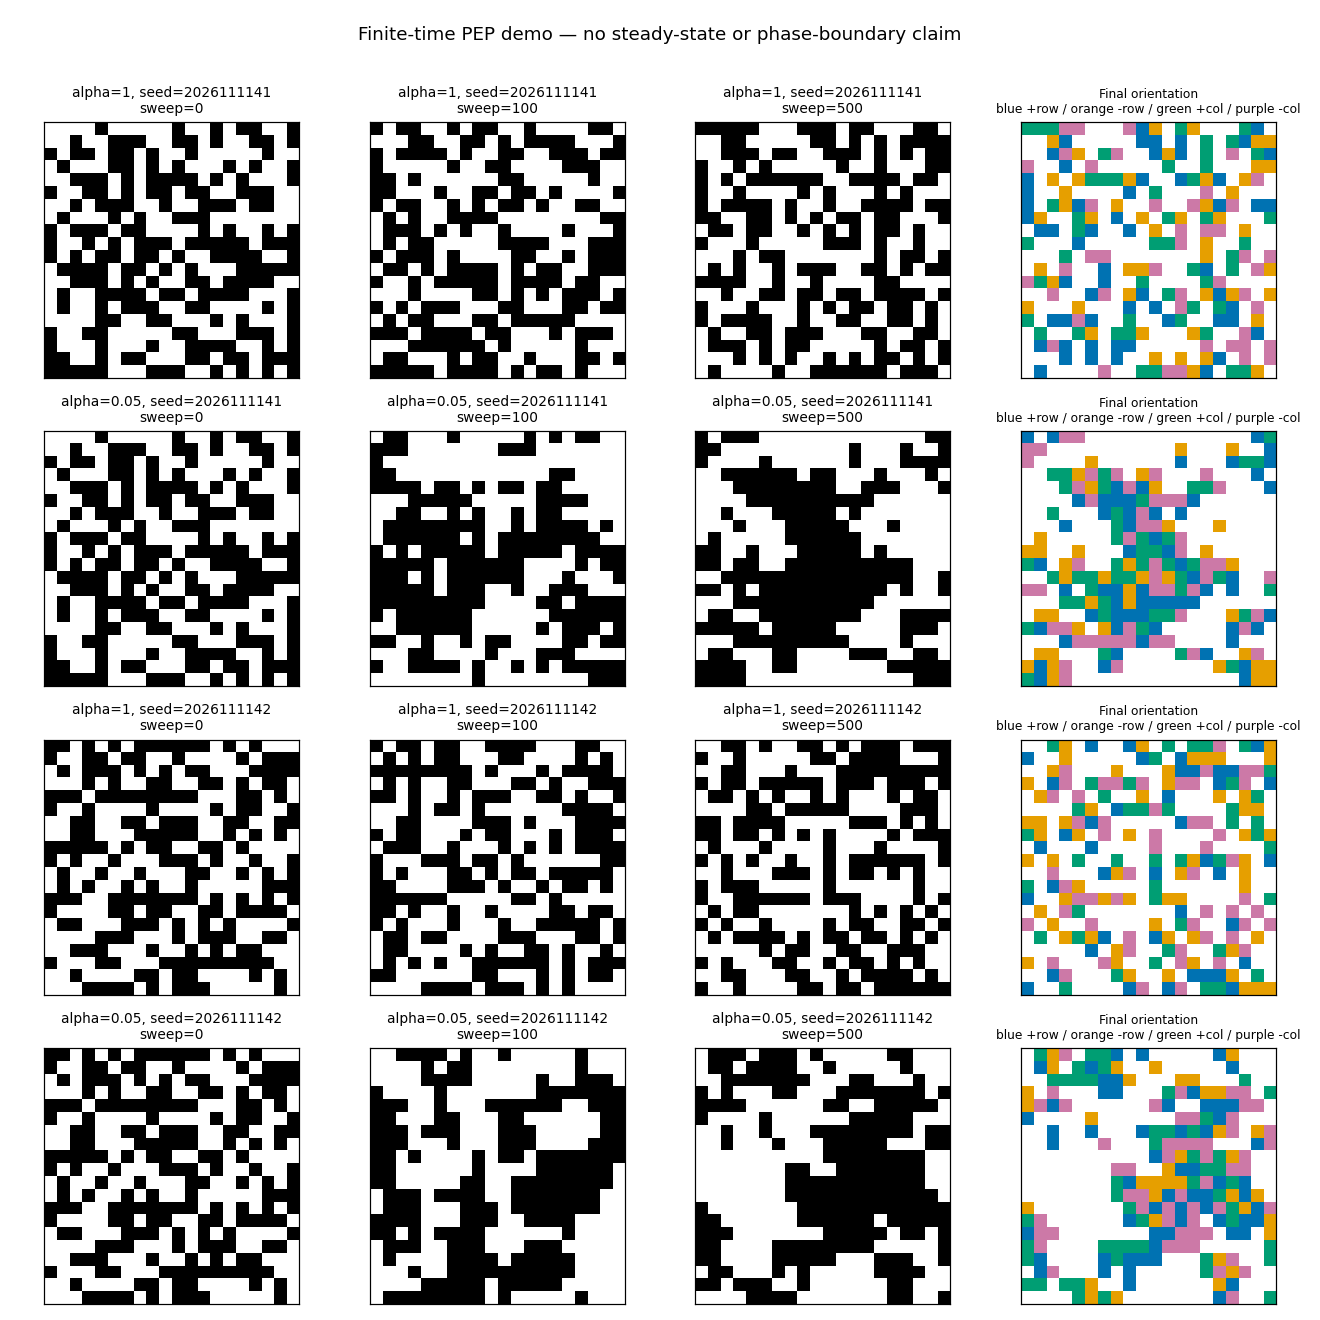

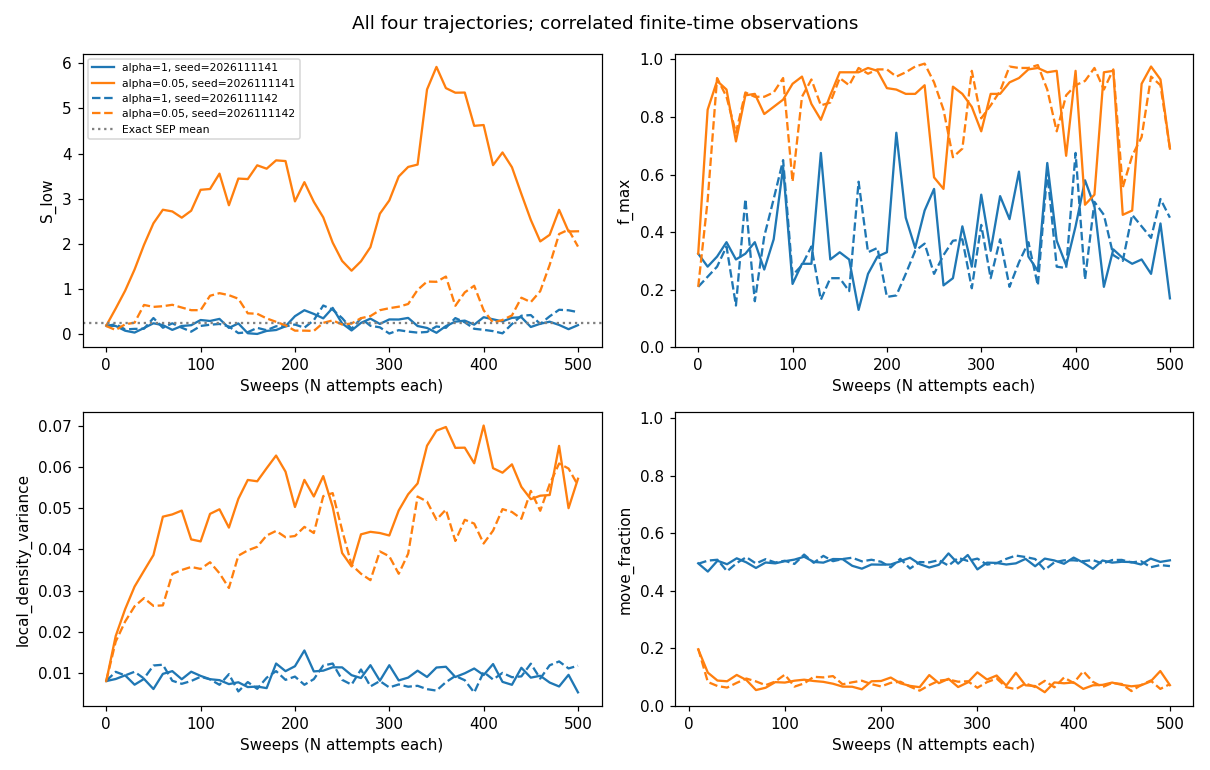

In [9]:
if RUN.is_dir() and (RUN/"summary.json").is_file():
    summary=json.loads((RUN/"summary.json").read_text())
    config=json.loads((RUN/"config.json").read_text())
    fig,axes=plt.subplots(len(summary),4,figsize=(12,3*len(summary)),squeeze=False)
    direction_cmap=matplotlib.colors.ListedColormap(["white","#0072B2","#E69F00","#009E73","#CC79A7"])
    for row,r in enumerate(summary):
        snap=np.load(RUN/r["tag"]/"snapshots.npz",allow_pickle=False)
        for col,(sweep,n) in enumerate(zip(snap["sweeps"],snap["occupation"])):
            axes[row,col].imshow(n,cmap="binary",vmin=0,vmax=1,interpolation="nearest",origin="lower")
            axes[row,col].set_title(f"alpha={r['alpha']:g}, seed={r['seed']}\nsweep={sweep}",fontsize=9)
        axes[row,3].imshow(snap["orientation"][-1]+1,cmap=direction_cmap,vmin=0,vmax=4,
                           interpolation="nearest",origin="lower")
        axes[row,3].set_title("Final orientation\nblue +row / orange -row / green +col / purple -col",fontsize=8)
        for ax in axes[row]:ax.set_xticks([]);ax.set_yticks([])
    fig.suptitle("Finite-time PEP demo — no steady-state or phase-boundary claim")
    fig.tight_layout(rect=(0,0,1,0.975))
    fig.savefig(RUN/"snapshots.png",dpi=140)
    plt.show()

    fig,axes=plt.subplots(2,2,figsize=(11,7))
    styles=["-","--"]
    for r in summary:
        rows=json.loads((RUN/r["tag"]/"measurements.json").read_text())
        color="tab:blue" if r["alpha"]==1 else "tab:orange"
        style=styles[config["seeds"].index(r["seed"])]
        for ax,obs in zip(axes.flat,["S_low","f_max","local_density_variance","move_fraction"]):
            valid=[x for x in rows if x[obs] is not None]
            ax.plot([x["sweep"] for x in valid],[x[obs] for x in valid],
                    color=color,linestyle=style,label=f"alpha={r['alpha']:g}, seed={r['seed']}")
            ax.set(xlabel="Sweeps (N attempts each)",ylabel=obs)
    N=round(config["density"]*config["L"]**2);M=config["L"]**2
    axes[0,0].axhline(N*(M-N)/(M*(M-1)),color="gray",linestyle=":",label="Exact SEP mean")
    axes[0,0].legend(fontsize=7)
    axes[0,1].set_ylim(0,1.02);axes[1,1].set_ylim(0,1.02)
    fig.suptitle("All four trajectories; correlated finite-time observations")
    fig.tight_layout()
    fig.savefig(RUN/"time_series.png",dpi=140)
    plt.show()
    print(json.dumps(json.loads((RUN/"status.json").read_text()),indent=2))
else:
    print("No run directory found. Set RUN_DEMO=True in section 5, or point RUN at a completed folder.")


## 7 — 结果能支持什么？

- `IMPLEMENTATION_CHECKS_PASSED` 支持上述 PEP 实现及部分精确极限，不代表稳态采样已合格。
- 快照显示的是 500 sweeps 内的有限时间结构；即使出现团块，也不能据此宣称 MIPS 或 stationary phase coexistence。
- alpha=1 是**无吸引力 SEP**基线，不等于旧 notebook 的 T=0.4 attractive lattice gas。
- $f_{max}$ 随 density 增大本来就可能增大，高密度随机占据也可能贯通；必须结合 density-matched baseline、空间结构及时间尺度理解。
- 当前 4 条轨迹既不是 activity–density heatmap，也不是 expTM training set。保存朝向使后续可以研究 joint state；只用 occupation 训练会丢弃方向信息。
- 若将来选择扫描 activity–density，先明确 density 与 persistence 的范围、初态、独立验证、预算和停机条件；本版不自动执行。
- 这次对已有工作的延伸是 PEP 实现与学习，不改变旧 equilibrium NOT READY 或已关闭的研究方向。

**先自己想两个问题：** 为什么 alpha 越小运动越持续？为什么固定 N 时用平均 density 当热图颜色无法辨别聚集？

**本次决策：** 保留实现、精确检查及有限时间示例，结束本次固定预算任务。下一步是否生成训练数据，应在选定模型和可靠采样标准后另行决定。
